<a href="https://colab.research.google.com/github/RoihansLab/Data-Mining-Project/blob/main/youtube_comment_sentiment/Zero-Shot_Labeling/Salinan_dari_Pre_trained_Transformer_baru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Analisis Sentimen Publik terhadap AI yang Menggantikan Pekerjaan Manusia**

**Mata Kuliah:** Data Mining

**Nama Anggota Kelompok:**

1.   Muhammad Rafa Enrico (Ketua)
2.   Roihan Saputra

**Kelas TI-3C**

**Program Studi:** D4 Teknologi Rekayasa Komputer, Politeknik Negeri Semarang

## Rumusan Masalah
1. Bagaimana sebaran sentimen publik (positif, negatif, netral, dan tidak relevan) terhadap isu AI yang menggantikan pekerjaan manusia berdasarkan komentar YouTube?
2. Algoritma klasifikasi mana di antara Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression yang memberikan performa terbaik untuk diimplementasikan sebagai model otomatisasi deteksi sentimen publik?

## Tujuan
1. Mengetahui sebaran sentimen publik terhadap isu AI yang menggantikan pekerjaan manusia.
2. Menemukan model klasifikasi yang paling tangguh (robust) untuk mengotomatisasi proses pelabelan sentimen pada data komentar di masa depan.

## Alur Notebook
1. **Import library** dan kunci random state (`SEED = 42`).
2. **Memuat data** hasil *scraping* 6 video YouTube dan memahami isinya.
3. **Preprocessing** sampai menjadi data bersih `youtube_comments_clean_EDA.csv`.
4. **EDA** untuk melihat komposisi data bersih.
5. **Pelabelan**: Nemotron 3 Ultra (LLM lewat API) dibandingkan dengan mDeBERTa-v3 multibahasa (NLI lokal di GPU) pada gold set, lalu konfigurasi terbaik melabeli seluruh data menjadi `youtube_comments_gold.csv`. File ini menjadi masukan notebook klasifikasi (Bab 6).

# **1. Import Library**

Semua library dipasang dan di-import di sel ini, termasuk `openai` (API NVIDIA), `python-dotenv` (membaca API key dari `.env`), serta `transformers` + `torch` (mDeBERTa). `SEED = 42` mengunci semua sumber acak (`random`, `numpy`, `torch`, `langdetect`) supaya hasil bisa diulang.

In [1]:
%pip install youtube-comment-downloader langdetect lingua-language-detector transformers torch emoji sentencepiece tiktoken openai python-dotenv --quiet
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay
from langdetect import detect, detect_langs, DetectorFactory, LangDetectException
from lingua import Language, LanguageDetectorBuilder
from transformers import pipeline
import torch
import joblib
import re
import os
import csv
import time
import unicodedata
from tqdm import tqdm
from collections import Counter
from openai import OpenAI, RateLimitError, APIConnectionError, InternalServerError
from dotenv import load_dotenv, find_dotenv
import random

# Kunci semua sumber acak supaya hasil bisa diulang persis sama
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DetectorFactory.seed = SEED



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


W1025 00:42:14.511000 25000 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


# **2. Memuat Data dan Memahami Data**

**Fitur yang Kami Ambil:**
1. `video_url`: URL dari 6 video YouTube yang menjadi sumber data.
2. `author`: nama akun penulis komentar.
3. `comment`: isi teks komentar.
4. `likes`: jumlah *like* pada komentar.
5. `time`: waktu komentar dibuat, relatif terhadap tanggal *web scraping* dilakukan.


In [2]:
# Deteksi otomatis lokasi dataset (Google Colab vs VSCode / Lokal)
if os.path.exists('/content/youtube_comments.csv'):
    # Google Colab
    path_data = '/content/youtube_comments.csv'
elif os.path.exists('../../datasets/youtube_comments.csv'):
    # VSCode (dijalankan dari folder notebook)
    path_data = '../../datasets/youtube_comments.csv'
elif os.path.exists('datasets/youtube_comments.csv'):
    # VSCode (dijalankan dari root project)
    path_data = 'datasets/youtube_comments.csv'
else:
    path_data = 'youtube_comments.csv'

df = pd.read_csv(path_data)
print(f"Data mentah dimuat dari: {path_data} ({len(df)} baris)")
jumlah_baris_awal = len(df)  # jumlah baris sebelum preprocessing
df


Data mentah dimuat dari: ../../datasets/youtube_comments.csv (4458 baris)


,video_url,author,comment,likes,time
0,https://www.youtube.com/watch?v=t2WmNcToB3I,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,2 maanden geleden
1,https://www.youtube.com/watch?v=t2WmNcToB3I,@robidarmawan71198,Menurut saya jika semua pengusaha berpikiran s...,189,2 maanden geleden
2,https://www.youtube.com/watch?v=t2WmNcToB3I,@wooshstar,jujur ya sebagai seorang yang bekerja di bidan...,6,2 maanden geleden (bewerkt)
3,https://www.youtube.com/watch?v=t2WmNcToB3I,@kadaladal7,Gw sebagai illustrator susah bener dapet klien...,588,2 maanden geleden
4,https://www.youtube.com/watch?v=t2WmNcToB3I,@Bagas_betok,Niat untung -> efesiensi phk->produksi mening...,85,2 maanden geleden
...,...,...,...,...,...
4453,https://www.youtube.com/watch?v=0LOHWGQwKtM,@HMF-7s,There’s a real awakening that cannot be stoppe...,0,5 maanden geleden
4454,https://www.youtube.com/watch?v=0LOHWGQwKtM,@fr0z3nk0,I'm a software engineer with 20 years of exper...,0,5 maanden geleden (bewerkt)
4455,https://www.youtube.com/watch?v=0LOHWGQwKtM,@nalen5050,so many way to discard that... I'll just take ...,2,5 maanden geleden
4456,https://www.youtube.com/watch?v=0LOHWGQwKtM,@georgioszampoukis,@nalen5050 Are you a software engineer? Beca...,0,5 maanden geleden


**Hasil `info()`:**

Ada 4.458 baris dan 5 kolom tanpa nilai kosong. Semua kolom bertipe teks, termasuk `likes` yang seharusnya angka, karena hasil *scraping* menyimpan semuanya sebagai string. Kolom `time` tidak dipakai dan dibuang setelah pengecekan duplikat (3.2), sedangkan `likes` disimpan untuk EDA dan diubah menjadi angka di 3.9.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4458 entries, 0 to 4457
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   video_url  4458 non-null   str  
 1   author     4458 non-null   str  
 2   comment    4458 non-null   str  
 3   likes      4458 non-null   str  
 4   time       4458 non-null   str  
dtypes: str(5)
memory usage: 1.2 MB


**Hasil dari Describe :**

1. count (Jumlah data) : Total baris data yang terisi (tidak kosong/null) pada kolom tersebut.
2. Unique (Keunikan / Variasi Data): Jumlah nilai yang benar-benar berbeda (tidak kembar) di dalam kolom tersebut.
3. Top (Nilai Paling Sering Muncul / Modus) : Data atau teks apa yang frekuensi kemunculannya paling tinggi di kolom itu.
4. Freq (Frequency / Frekuensi) :
Seberapa banyak si nilai top tadi muncul di dalam dataset.


Tabel ini menunjukkan karakteristik data teks kami. Count adalah total data yang kami miliki, Unique menunjukkan seberapa banyak variasi datanya, Top adalah isi data yang paling dominan atau sering muncul, dan Freq menunjukkan berapa kali nilai Top tersebut muncul di dalam dataset

In [4]:
df.describe().T

,count,unique,top,freq
video_url,4458,6,https://www.youtube.com/watch?v=7Pq-S557XQU,1500
author,4458,3320,@edward-broo,36
comment,4458,4406,Up,6
likes,4458,241,0,2400
time,4458,62,2 maanden geleden,933


# **3. Preprocessing Data**

Pada tahap preprocessing, kami menerapkan pendekatan yang sistematis dan terstruktur untuk memastikan kualitas data mentah sebelum masuk ke tahap analisis dan pemodelan.

Urutan langkahnya: 3.1 nilai kosong → 3.2 duplikat baris → 3.3 penyesuaian fitur → 3.4 pembersihan teks → 3.5 spam judi online → 3.6 duplikat isi komentar → 3.7 komentar pendek → 3.8 deteksi bahasa → 3.9 kolom likes → 3.10 menyimpan data bersih → 3.11 ringkasan masalah data.

## **3.1 Nilai Kosong (Null)**

**Intinya:** Nilai kosong (null) adalah kolom yang tidak berisi data apa pun, seperti sel kosong di Excel. Baris seperti ini tidak dapat dipakai model sehingga dibuang.

**Contoh:** komentar yang kolom `comment`-nya kosong tidak memuat opini, sehingga barisnya dihapus. (Pada data kami tidak ditemukan nilai kosong.)

**Mengapa nilai kosong (null) harus ditangani?**

1. **Menyebabkan error saat pelatihan model:** Sebagian besar algoritma *machine learning*, termasuk Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression yang kami gunakan, bekerja dengan operasi numerik seperti perkalian matriks dan perhitungan jarak vektor. Algoritma tersebut tidak dapat mengolah nilai kosong (NaN/null), sehingga proses pelatihan akan menghasilkan error.

2. **Tidak mengandung informasi:** Dalam analisis sentimen, komentar yang bernilai null tidak memuat opini apa pun sehingga tidak ada pola yang dapat dipelajari oleh model.

3. **Mengganggu ekstraksi fitur:** Pada tahap ekstraksi fitur menggunakan TF-IDF, baris tanpa teks dapat membuat matriks representasi kata menjadi tidak konsisten.

In [5]:
df.isnull().sum()

video_url    0
author       0
comment      0
likes        0
time         0
dtype: int64

**Hasil pengecekan:**

Tidak ada nilai kosong di kelima kolom, jadi tidak ada baris yang dibuang pada langkah ini.

## **3.2 Data Duplikat**

**Intinya:** Baris duplikat adalah baris yang isinya sama persis di semua kolom (video, penulis, komentar, jumlah *like*, dan waktu), sehingga hanya salinan. Satu baris disimpan dan salinannya dihapus.

**Contoh:** baris yang muncul dua kali dengan isi yang persis sama dihitung sebagai 1 baris saja.

**Mengapa data duplikat harus dihapus?**

1. **Mencegah kebocoran data (*data leakage*):** Saat data dibagi menjadi data latih dan data uji (misalnya 80:20), kalimat yang sama dapat masuk ke kedua bagian sekaligus. Akibatnya, model diuji menggunakan data yang sudah pernah dilihat saat pelatihan.

2. **Mencegah akurasi semu:** Kebocoran data tersebut dapat membuat akurasi model tampak sangat tinggi, padahal model hanya "menghafal" komentar duplikat, bukan memahami pola kalimat baru.

3. **Mencegah bias bobot kata:** Jika satu komentar (misalnya komentar spam atau bot) muncul berkali-kali, kata-kata di dalamnya akan dianggap terlalu penting dalam pembobotan TF-IDF sehingga model menjadi bias.

4. **Efisiensi komputasi:** Memproses teks yang sama berulang kali hanya menambah penggunaan memori dan waktu pelatihan tanpa menambah informasi baru.

In [6]:
df.duplicated().sum()

np.int64(11)

**Hasil pengecekan:**

Ditemukan **11 baris duplikat**, yaitu baris yang identik pada seluruh kolom (video, penulis, isi komentar, jumlah *like*, dan waktu). Baris pertama dari setiap kelompok dipertahankan dan salinannya dihapus, sehingga tersisa 4.447 baris.

Setelah itu kolom `time` dibuang karena hanya berisi waktu relatif terhadap tanggal *scraping* (dalam bahasa Belanda, misalnya "2 maanden geleden"). Kolom `likes` tetap disimpan untuk EDA dan dibersihkan di 3.9.

In [7]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [8]:
df

,video_url,author,comment,likes,time
0,https://www.youtube.com/watch?v=t2WmNcToB3I,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,2 maanden geleden
1,https://www.youtube.com/watch?v=t2WmNcToB3I,@robidarmawan71198,Menurut saya jika semua pengusaha berpikiran s...,189,2 maanden geleden
2,https://www.youtube.com/watch?v=t2WmNcToB3I,@wooshstar,jujur ya sebagai seorang yang bekerja di bidan...,6,2 maanden geleden (bewerkt)
3,https://www.youtube.com/watch?v=t2WmNcToB3I,@kadaladal7,Gw sebagai illustrator susah bener dapet klien...,588,2 maanden geleden
4,https://www.youtube.com/watch?v=t2WmNcToB3I,@Bagas_betok,Niat untung -> efesiensi phk->produksi mening...,85,2 maanden geleden
...,...,...,...,...,...
4453,https://www.youtube.com/watch?v=0LOHWGQwKtM,@HMF-7s,There’s a real awakening that cannot be stoppe...,0,5 maanden geleden
4454,https://www.youtube.com/watch?v=0LOHWGQwKtM,@fr0z3nk0,I'm a software engineer with 20 years of exper...,0,5 maanden geleden (bewerkt)
4455,https://www.youtube.com/watch?v=0LOHWGQwKtM,@nalen5050,so many way to discard that... I'll just take ...,2,5 maanden geleden
4456,https://www.youtube.com/watch?v=0LOHWGQwKtM,@georgioszampoukis,@nalen5050 Are you a software engineer? Beca...,0,5 maanden geleden


In [9]:
df = df.drop(columns=["time"])
df


,video_url,author,comment,likes
0,https://www.youtube.com/watch?v=t2WmNcToB3I,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol d...,413
1,https://www.youtube.com/watch?v=t2WmNcToB3I,@robidarmawan71198,Menurut saya jika semua pengusaha berpikiran s...,189
2,https://www.youtube.com/watch?v=t2WmNcToB3I,@wooshstar,jujur ya sebagai seorang yang bekerja di bidan...,6
3,https://www.youtube.com/watch?v=t2WmNcToB3I,@kadaladal7,Gw sebagai illustrator susah bener dapet klien...,588
4,https://www.youtube.com/watch?v=t2WmNcToB3I,@Bagas_betok,Niat untung -> efesiensi phk->produksi mening...,85
...,...,...,...,...
4453,https://www.youtube.com/watch?v=0LOHWGQwKtM,@HMF-7s,There’s a real awakening that cannot be stoppe...,0
4454,https://www.youtube.com/watch?v=0LOHWGQwKtM,@fr0z3nk0,I'm a software engineer with 20 years of exper...,0
4455,https://www.youtube.com/watch?v=0LOHWGQwKtM,@nalen5050,so many way to discard that... I'll just take ...,2
4456,https://www.youtube.com/watch?v=0LOHWGQwKtM,@georgioszampoukis,@nalen5050 Are you a software engineer? Beca...,0


## **3.3 Menyesuaikan Fitur `video_url` dan `author`**

**Intinya:** dua kolom ini diubah menjadi bentuk yang lebih berguna dan lebih aman.

- `video_url` → `video_title`: URL diganti judul video supaya mudah dibaca saat EDA. Judul juga dipakai sebagai kelompok pada uji *leave-one-video-out* di notebook klasifikasi.
- `author` → `author_id`: nama akun diganti nomor urut (anonimisasi). Data tidak lagi memuat identitas penulis, tetapi komentar dari akun yang sama tetap bisa dikenali.

`video_url` --> `video_title`

In [10]:
title = {
    "t2WmNcToB3I": "Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!",
    "F8pz5wIO6gA": "Manusia Belum Tergantikan AI Karena Satu Hambatan Ini",
    "7Pq-S557XQU": "Humans Need Not Apply - CGP Grey",
    "SDich6serU0": "The EXACT moment AI took my job...",
    "s1c4Ji6tNdw": "UK unemployment soars: is AI already taking our jobs?",
    "0LOHWGQwKtM": "AI is taking their jobs. But they're fighting back.",
}

df["video_title"] = df["video_url"].str[-11:].map(title)
df["video_title"].isna().sum()

np.int64(0)

In [11]:
df = df [["video_title", "author", "comment", "likes"]]
df

,video_title,author,comment,likes
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol d...,413
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,@robidarmawan71198,Menurut saya jika semua pengusaha berpikiran s...,189
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,@wooshstar,jujur ya sebagai seorang yang bekerja di bidan...,6
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,@kadaladal7,Gw sebagai illustrator susah bener dapet klien...,588
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,@Bagas_betok,Niat untung -> efesiensi phk->produksi mening...,85
...,...,...,...,...
4453,AI is taking their jobs. But they're fighting ...,@HMF-7s,There’s a real awakening that cannot be stoppe...,0
4454,AI is taking their jobs. But they're fighting ...,@fr0z3nk0,I'm a software engineer with 20 years of exper...,0
4455,AI is taking their jobs. But they're fighting ...,@nalen5050,so many way to discard that... I'll just take ...,2
4456,AI is taking their jobs. But they're fighting ...,@georgioszampoukis,@nalen5050 Are you a software engineer? Beca...,0


`author` --> `author_id`

In [12]:
df['author'].head()

0            @aprie_rdw
1    @robidarmawan71198
2            @wooshstar
3           @kadaladal7
4          @Bagas_betok
Name: author, dtype: str

In [13]:
df['author_id'] = df["author"].factorize()[0]
df['author_id'].nunique()

3320

In [14]:
df['author_id'].head()

0    0
1    1
2    2
3    3
4    4
Name: author_id, dtype: int64

In [15]:
df.drop(columns=["author"], inplace=True)
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi mening...,85,4
...,...,...,...,...
4453,AI is taking their jobs. But they're fighting ...,There’s a real awakening that cannot be stoppe...,0,3317
4454,AI is taking their jobs. But they're fighting ...,I'm a software engineer with 20 years of exper...,0,3318
4455,AI is taking their jobs. But they're fighting ...,so many way to discard that... I'll just take ...,2,3319
4456,AI is taking their jobs. But they're fighting ...,@nalen5050 Are you a software engineer? Beca...,0,3313


## **3.4 Pembersihan Teks**

Isi komentar dirapikan tanpa mengubah maknanya: mention, URL, dan karakter tak terlihat dibuang, lalu spasi dirapikan. Huruf besar-kecil, emoji, dan tanda baca **tidak** dibuang karena ikut membawa sikap penulis (misalnya "TAKUT BANGET 😭") dan tetap bisa dibaca oleh Nemotron maupun mDeBERTa.

Setiap langkah dicek sebelum dan sesudah: jumlah komentar yang masih terkena harus menjadi 0.

### **3.4.1 Mention (@username)**

**Intinya:** mention adalah nama akun yang dibalas (@nama). Nama akun bukan opini, jadi diganti spasi.

**Contoh:** `@SepulangSekolah gas bang koi` menjadi `gas bang koi`.

Mention mirip URL: tidak mengandung opini dan hanya menambah kata unik yang tidak berguna (*noise*) pada vocabulary TF-IDF. Pada data kami ada 923 komentar yang memuat mention.

In [16]:
df["comment"].str.contains(r"@\S+").sum()

np.int64(923)

In [17]:
df["comment"] = df["comment"].str.replace(r"@\S+", " ", regex=True)
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi mening...,85,4
...,...,...,...,...
4453,AI is taking their jobs. But they're fighting ...,There’s a real awakening that cannot be stoppe...,0,3317
4454,AI is taking their jobs. But they're fighting ...,I'm a software engineer with 20 years of exper...,0,3318
4455,AI is taking their jobs. But they're fighting ...,so many way to discard that... I'll just take ...,2,3319
4456,AI is taking their jobs. But they're fighting ...,Are you a software engineer? Because if you...,0,3313


In [18]:
df["comment"].str.contains(r"@\S+").sum()

np.int64(0)

### **3.4.2 URL**

**Intinya:** tautan (`http...` atau `www...`) dibuang karena tidak berisi opini, dan setiap tautan menjadi "kata" unik yang tidak berguna. Ada 11 komentar yang memuat URL.

In [19]:
df["comment"].str.contains(r"https?://\S+|www\.\S+").sum()

np.int64(11)

In [20]:
df["comment"] = df["comment"].str.replace(r"https?://\S+|www\.\S+", " ", regex=True)
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi mening...,85,4
...,...,...,...,...
4453,AI is taking their jobs. But they're fighting ...,There’s a real awakening that cannot be stoppe...,0,3317
4454,AI is taking their jobs. But they're fighting ...,I'm a software engineer with 20 years of exper...,0,3318
4455,AI is taking their jobs. But they're fighting ...,so many way to discard that... I'll just take ...,2,3319
4456,AI is taking their jobs. But they're fighting ...,Are you a software engineer? Because if you...,0,3313


In [21]:
df["comment"].str.contains(r"https?://\S+|www\.\S+").sum()

np.int64(0)

### **3.4.3 Karakter Tak Terlihat**

**Intinya:** karakter seperti *zero-width space* (`​`), *zero-width non-joiner* (`‌`), *word joiner* (`⁠`), dan BOM (`﻿`) tidak tampak di layar, tetapi membuat dua kata yang terlihat sama dianggap berbeda oleh komputer. Ada 273 komentar yang memuatnya.

Pola regex ditulis sebagai string biasa (bukan `r"..."`) supaya Python mengubah `​` menjadi karakter aslinya lebih dulu. Dengan begitu kode berjalan di pandas 2 (Colab) maupun pandas 3 (lokal).

In [22]:
df["comment"].str.contains("[\u200b\u200c\u2060\ufeff]").sum()

np.int64(273)

In [23]:
df["comment"] = df["comment"].str.replace("[\u200b\u200c\u2060\ufeff]", "", regex=True)
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi mening...,85,4
...,...,...,...,...
4453,AI is taking their jobs. But they're fighting ...,There’s a real awakening that cannot be stoppe...,0,3317
4454,AI is taking their jobs. But they're fighting ...,I'm a software engineer with 20 years of exper...,0,3318
4455,AI is taking their jobs. But they're fighting ...,so many way to discard that... I'll just take ...,2,3319
4456,AI is taking their jobs. But they're fighting ...,Are you a software engineer? Because if you...,0,3313


In [24]:
df["comment"].str.contains("[\u200b\u200c\u2060\ufeff]").sum()

np.int64(0)

### **3.4.4 Spasi Ganda, Spasi di Tepi, dan Baris Baru**

**Intinya:** semua spasi berlebih dan baris baru diganti satu spasi biasa. Ada 1.616 komentar yang terkena.

Alasannya:
1. **Mencegah kerusakan saat disimpan:** baris baru (`\n`) di dalam komentar bisa membuat baris data terpecah saat CSV dibuka di Excel.
2. **Tokenisasi rapi:** satu spasi antarkata memudahkan TF-IDF dan tokenizer model memotong kata dengan tepat.
3. **Prompt rapi:** komentar dikirim ke LLM sebagai satu baris.

In [25]:
(df["comment"] != df["comment"].str.split().str.join(" ")).sum()

np.int64(1616)

In [26]:
df["comment"] = df["comment"].str.split().str.join(" ")
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi meningk...,85,4
...,...,...,...,...
4453,AI is taking their jobs. But they're fighting ...,There’s a real awakening that cannot be stoppe...,0,3317
4454,AI is taking their jobs. But they're fighting ...,I'm a software engineer with 20 years of exper...,0,3318
4455,AI is taking their jobs. But they're fighting ...,so many way to discard that... I'll just take ...,2,3319
4456,AI is taking their jobs. But they're fighting ...,Are you a software engineer? Because if you we...,0,3313


In [27]:
(df["comment"] != df["comment"].str.split().str.join(" ")).sum()

np.int64(0)

## **3.5 Spam Judi Online**

**Intinya:** sebagian komentar adalah promosi situs judi online, bukan opini. Spam dikenali dengan dua aturan:

1. **Huruf bergaya** (blok Unicode *Mathematical Alphanumeric*, misalnya 𝘽𝙀𝙍𝙆𝘼𝙃99) yang dipakai spammer untuk menghindari filter.
2. **Kata khas judi:** maxwin, maxwen, scatter, jackpot, gacor, slot, togel.

Komentar yang memenuhi salah satu aturan dibuang (33 komentar) dan disimpan di `df_spam`. Satu komentar candaan tentang dukun togel ikut terbuang; jumlahnya kecil sehingga diterima.

In [28]:
bergaya = df["comment"].str.contains("[\U0001D400-\U0001D7FF]")
print("Jumlah:", bergaya.sum())
df[bergaya]

Jumlah: 28


,video_title,comment,likes,author_id
401,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,7:18 𝘽𝙀𝙍𝙆𝘼𝙃99 kayak pelarian paling nyaman 🐯,0,287
411,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,11:02 Paling the best selalu jadi pilihan utam...,0,296
446,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,13:03 gue suka vibe-nya 𝘽𝙀𝙍𝙆𝘼𝙃99 📣,0,325
452,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,8:31 Paling the best selalu pengen balik 𝘽𝙀𝙍𝙆𝘼...,0,331
455,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,5:39 𝘽𝙀𝙍𝙆𝘼𝙃99 tuh bikin nyaman parah.,0,334
463,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,12:10 𝘽𝙀𝙍𝙆𝘼𝙃99 itu santuy banget tempatnya.,0,341
491,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,0:10 ngopi sambil buka 𝘽𝙀𝙍𝙆𝘼𝙃99 itu wajib 👍🏻,0,367
492,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,3:10 Dijamin happy temen nongkrong terbaik 𝘽𝙀𝙍...,0,368
493,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,4:20 Profesional & on point 𝘽𝙀𝙍𝙆𝘼𝙃99 💼 hasilny...,0,369
494,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,9:09 Paling the best bener-bener nggak bikin b...,0,370


In [29]:
pd.set_option("display.max_colwidth", 140)

khas = df["comment"].str.contains(r"\b(?:maxwin|maxwen|scatter|jackpot|gacor|slot|togel)\b", case=False)
print("Jumlah:", khas.sum())
df[khas]

Jumlah: 5


,video_title,comment,likes,author_id
487,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Akhirnya aaaaaaaaaa nemuGaruda Ho ki dapet maxwin bet 2rb😎,0,363
488,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Mudah jepe nyaGaruda Hoki terjamin, grate A lah buat gua bisa rasain maxwin disitu😘",0,364
497,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Mantaaaaab..!!👍👍👍, isi sekali scatter nya. TerimakasihGaruda Ho ki sudah diberi maxwen gratisnyaa..😂😂",0,373
683,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Jackpot lagi dariGaruda Hoki, paling seneng bgt maen disini wd gope gampang bgt🙊💥",0,525
1551,Manusia Belum Tergantikan AI Karena Satu Hambatan Ini,AI tidak bisa menggantikan dukun togel karena sampai saat ini AI msih blum bisa memprediksi nomer togel,0,1170


In [30]:
spam = bergaya | khas
spam.sum()

np.int64(33)

In [31]:
df_spam = df[spam]                       # disimpan untuk EDA
df = df[~spam].reset_index(drop=True)
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,85,4
...,...,...,...,...
4409,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t give away from power...,0,3317
4410,AI is taking their jobs. But they're fighting back.,"I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by discussing with my ""arch...",0,3318
4411,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",2,3319
4412,AI is taking their jobs. But they're fighting back.,"Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem is not the AI, it is ...",0,3313


In [32]:
bergaya = df["comment"].str.contains("[\U0001D400-\U0001D7FF]")
khas = df["comment"].str.contains(r"\b(?:maxwin|maxwen|scatter|jackpot|gacor|slot|togel)\b", case=False)

(bergaya | khas).sum()

np.int64(0)

## **3.6 Duplikat Isi Komentar**

**Intinya:** berbeda dengan 3.2 yang membandingkan seluruh kolom, di sini yang dibandingkan hanya isi komentar, tanpa membedakan huruf besar-kecil. Komentar yang sama dari akun berbeda (misalnya "agree", "exactly", "ikr") hanya disimpan satu, supaya tidak masuk data latih dan data uji sekaligus (kebocoran data).

In [33]:
df["comment"].str.lower().duplicated().sum()

np.int64(59)

In [34]:
duplikat = df["comment"].str.lower().duplicated(keep=False)    # tandai semua salinan, termasuk yang pertama
df.loc[duplikat, "comment"].str.lower().sort_values().head(14)

23                               
838                              
3640                             
42                               
61                               
3546                             
65                               
67                               
580                              
1871                 -human brain
1916                 -human brain
2175                        agree
2169                        agree
615     banyak anak banyak rezeqi
Name: comment, dtype: str

In [35]:
df = df[~df["comment"].str.lower().duplicated()].reset_index(drop=True)
df["comment"].str.lower().duplicated().sum()

np.int64(0)

## **3.7 Komentar Kurang dari 3 Kata**

**Intinya:** komentar seperti "Up", "Gassss", atau satu emoji tidak memuat sikap terhadap AI dan tidak bisa dilabeli dengan yakin, jadi dibuang.

In [36]:
pendek = df["comment"].str.split().str.len() < 3
pendek.sum()

np.int64(305)

In [37]:
df[pendek].head(10)

,video_title,comment,likes,author_id
20,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Up?,133,20
22,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,bang koi,11,22
23,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,,3,23
24,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Up,4,24
30,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,🫨,2,30
31,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Ups,2,31
33,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,...,1,34
34,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Up👍,1,35
35,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Gassss,1,36
36,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Gaasss,0,38


In [38]:
df = df[~pendek].reset_index(drop=True)
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,85,4
...,...,...,...,...
4045,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t give away from power...,0,3317
4046,AI is taking their jobs. But they're fighting back.,"I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by discussing with my ""arch...",0,3318
4047,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",2,3319
4048,AI is taking their jobs. But they're fighting back.,"Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem is not the AI, it is ...",0,3313


In [39]:
(df["comment"].str.split().str.len() < 3).sum()

np.int64(0)

## **3.8 Deteksi Bahasa**

**Intinya:** setiap komentar ditandai berbahasa Indonesia atau Inggris dengan library **lingua**, yang hanya diminta memilih di antara dua bahasa itu.

- Kolom `keyakinan` berisi tingkat keyakinan lingua (0 sampai 1).
- Komentar dengan keyakinan di bawah 0,8 ditandai **"Tidak yakin"** lalu dibuang. Biasanya ini komentar campuran (*code-mixing*), bahasa lain, atau teks yang terlalu pendek atau aneh.
- Kolom `bahasa` disimpan untuk EDA.

In [40]:
detektor = LanguageDetectorBuilder.from_languages(Language.INDONESIAN, Language.ENGLISH).build()

bahasa = []
keyakinan = []

for teks in df["comment"]:
    hasil = detektor.compute_language_confidence_values(teks)[0]
    if hasil.language == Language.INDONESIAN:
        bahasa.append("Indonesia")
    else:
        bahasa.append("Inggris")
    keyakinan.append(hasil.value)

df["bahasa"] = bahasa
df["keyakinan"] = keyakinan
df.loc[df["keyakinan"] < 0.8, "bahasa"] = "Tidak yakin"
df[["comment", "bahasa", "keyakinan"]].head(10)

,comment,bahasa,keyakinan
0,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,Indonesia,0.977696
1,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",Indonesia,1.000000
2,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",Indonesia,1.000000
3,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",Indonesia,1.000000
4,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,Indonesia,1.000000
5,"Tokopedia hanya memanfaatkan market konsumen Indonesia, mereka gak mau mempekerjakan banyak orang Indonesia, lebih baik netizen Indonesi...",Indonesia,1.000000
6,gw berani taruhan kalo dampak buruk AI lebih banyak ketimbang manfaatnya,Indonesia,0.999996
7,"Bukan hanya AI yang mengubah dunia kerja, aplikasi online juga telah mengubah hampir semua bidang usaha. Jual beli kini banyak berpindah...",Indonesia,1.000000
8,Harvest Moon : Back to Nature wkwkwkw. mancing nyangkul bertani solusinya,Indonesia,0.892947
9,"BANG BAHAS DEMO YG GAK DI TAYANGIN DI TV, MALAH BUZZER PADA NGIRIM MEME DOKSLI",Indonesia,0.978642


In [41]:
df.groupby("bahasa")["keyakinan"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
bahasa,,,,,,,,
Indonesia,1437.0,0.99,0.03,0.8,1.00,1.0,1.00,1.0
Inggris,2492.0,0.98,0.03,0.8,0.99,1.0,1.00,1.0
Tidak yakin,121.0,0.69,0.09,0.5,0.63,0.7,0.76,0.8


In [42]:
df["bahasa"].value_counts()

bahasa
Inggris        2492
Indonesia      1437
Tidak yakin     121
Name: count, dtype: int64

In [43]:
print("Dibuang:", (df["bahasa"] == "Tidak yakin").sum())

df = df[df["bahasa"] != "Tidak yakin"].reset_index(drop=True)
df

Dibuang: 121


,video_title,comment,likes,author_id,bahasa,keyakinan
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,0,Indonesia,0.977696
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",189,1,Indonesia,1.000000
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",6,2,Indonesia,1.000000
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",588,3,Indonesia,1.000000
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,85,4,Indonesia,1.000000
...,...,...,...,...,...,...
3924,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t give away from power...,0,3317,Inggris,1.000000
3925,AI is taking their jobs. But they're fighting back.,"I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by discussing with my ""arch...",0,3318,Inggris,1.000000
3926,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",2,3319,Inggris,1.000000
3927,AI is taking their jobs. But they're fighting back.,"Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem is not the AI, it is ...",0,3313,Inggris,1.000000


**Cek manual:** 60 komentar acak dari tiap bahasa (`random_state=SEED`) ditampilkan untuk memastikan hasil lingua masuk akal. Setelah itu kolom `keyakinan` dibuang karena tidak dipakai lagi.

In [44]:
df[df["bahasa"] == "Indonesia"].sample(60, random_state=SEED)[["comment", "keyakinan"]]

,comment,keyakinan
598,"Kalau semuanya ai yg gantiin kerjaan manusia, terus barang hasil produksi siapa yg beli? Yg bikin perputaran ekonomi kan jg dari pekerja...",1.000000
759,Aku berasa lagi ikut dosen kasih kuliah hihi,0.999254
634,Apakah yajuj majuj adalah e ai yang memberontak dan mengendalikan jutaan robot untuk memusnahkan umat manusia hmm menarik,1.000000
1157,Mereka takut obat kanker ditemukan AI mungkin😂,0.999977
912,memang itu tujuan AI,0.995926
1044,Elon musk berencana membangun data center dan AI development di luar angkasa dg mendapatkan energy langsung dr matahari,0.999966
767,Lupakan Wapres biar ga stress,0.979129
1404,HIDUP AI !!,0.977527
259,bedanya penemuan baru sebelum2nya spesifik ke satu bidang. Satu penemuan = 1 bidang. 1 pekerjaan ilang = muncul pekerjaan lain. Kalau AI...,1.000000
316,Tar habis magrib gua tonton,0.875454


In [45]:
df[df["bahasa"] == "Inggris"].sample(60, random_state=SEED)[["comment", "keyakinan"]]

,comment,keyakinan
3648,"It’s simply a marketing strategy to sell mobile phones. If you believe your job could be automated, consider learning new skills. No one...",1.000000
3507,Maybe we should've bought an expert on?,0.990372
2829,"As a person originally from Africa, I had it when people use the ""kids starving in Africa"" comment. All continents have some starving st...",0.999916
3587,"how? if barely anyone has jobs, who pays artists?",0.998353
2494,Bruh unless we're absolute idiots about it it will only create more wealth and more free time. It's a win/win situation,0.999872
3910,"gen that i know, they live in a fear that if they won't use ai, then they will lose their job. In their heads they just HAVE to do that ...",1.000000
3711,Its a pretty vacant student level discussion.,0.996299
2245,"Even before AI, a good (back end) programmer is the one that makes programming easier, faster and simpler. So yes, the goal of a program...",1.000000
2294,"This is the equivalent of the thinking that death is required to give life meaning. No, this is a fallacious idea. There is no requireme...",1.000000
3133,"That's what they see the mass of humanity as: their property, farm animals they can use and dispose of at their will. They only allow hu...",1.000000


In [46]:
df = df.drop(columns=["keyakinan"])

## **3.9 Kolom `likes`**

Likes dipakai untuk EDA, jadi diubah dari teks menjadi angka. `astype(int)` langsung tidak bisa karena YouTube menulis likes besar sebagai `4,4K` atau `14K`. Koma diganti titik dan `K` diganti `e3` (ribu), sehingga `4,4K` → `4.4e3` → 4.400.

In [47]:
df["likes"] = df["likes"].str.replace(",", ".").str.replace("K", "e3").astype(float).astype(int)
df["likes"].describe()

count     3929.000000
mean        93.507254
std       1112.160899
min          0.000000
25%          0.000000
50%          0.000000
75%          3.000000
max      31000.000000
Name: likes, dtype: float64

**Hasil:** `likes` sekarang bertipe angka (`int64`) tanpa nilai kosong. Median 0 *like*, sekitar 87% komentar mendapat paling banyak 10 *like*, dan komentar paling populer mencapai 31.000 *like*.

## **3.10 Menyimpan Data Bersih**

Data bersih disimpan sebagai `youtube_comments_clean_EDA.csv` (beserta salinan `youtube_comments_clean.csv`) di folder `datasets`. File inilah yang dipakai EDA (Bab 4) dan pelabelan (Bab 5). Kolomnya: `video_title`, `comment`, `likes`, `author_id`, dan `bahasa`.

In [48]:
# Simpan DataFrame ke CSV (Google Colab vs VSCode / Lokal)
if os.path.exists('/content'):
    # Google Colab
    save_path = '/content/youtube_comments_clean_EDA.csv'
    df.to_csv(save_path, index=False)
    print(f"Dataset berhasil disimpan di Colab: {save_path}")
    try:
        from google.colab import files
        files.download(save_path)
    except Exception as e:
        print(f"Download otomatis browser dilewati: {e}")
else:
    # VSCode / Lingkungan Lokal: simpan ke folder datasets
    if os.path.exists('../../datasets'):
        save_path = '../../datasets/youtube_comments_clean_EDA.csv'
        df.to_csv('../../datasets/youtube_comments_clean.csv', index=False)
    elif os.path.exists('datasets'):
        save_path = 'datasets/youtube_comments_clean_EDA.csv'
        df.to_csv('datasets/youtube_comments_clean.csv', index=False)
    else:
        save_path = 'youtube_comments_clean_EDA.csv'

    df.to_csv(save_path, index=False)
    print(f"Dataset berhasil disimpan di folder datasets: {save_path}")


Dataset berhasil disimpan di folder datasets: ../../datasets/youtube_comments_clean_EDA.csv


## **3.11 Ringkasan Masalah Data (Data Understanding)**

Pemeriksaan kualitas data dilakukan sekaligus dengan pembersihannya di 3.1 sampai 3.9. Tabel berikut merangkum semua masalah yang ditemukan pada data mentah dan cara penanganannya.

| Masalah | Jumlah | Penanganan | Bagian |
|---|---|---|---|
| Nilai kosong | 0 | tidak ada yang perlu dibuang | 3.1 |
| Baris duplikat (semua kolom sama) | 11 baris | dihapus | 3.2 |
| Mention (@username) | 923 komentar | mention dibuang dari teks | 3.4.1 |
| URL | 11 komentar | URL dibuang dari teks | 3.4.2 |
| Karakter tak terlihat (misalnya *zero-width space*) | 273 komentar | karakter dibuang dari teks | 3.4.3 |
| Spasi ganda, spasi di tepi, atau baris baru | 1.616 komentar | dirapikan menjadi satu spasi | 3.4.4 |
| Spam judi online | 33 komentar | dihapus | 3.5 |
| Isi komentar kembar | 59 komentar | dihapus, satu salinan disimpan | 3.6 |
| Komentar kurang dari 3 kata | 305 komentar | dihapus | 3.7 |
| Bahasa tidak yakin (keyakinan < 0,8) | 121 komentar | dihapus | 3.8 |
| `likes` berupa teks (misalnya `4,4K`) | 42 nilai | diubah menjadi angka | 3.9 |

**Jumlah data di setiap tahap yang membuang baris:**

| Tahap | Sisa komentar |
|---|---|
| Data mentah | 4.458 |
| Setelah baris duplikat dihapus (3.2) | 4.447 |
| Setelah spam dihapus (3.5) | 4.414 |
| Setelah isi kembar dihapus (3.6) | 4.355 |
| Setelah komentar pendek dihapus (3.7) | 4.050 |
| Setelah bahasa tidak yakin dihapus (3.8) | **3.929** |

Secara keseluruhan, 529 komentar (11,9%) dibuang dan 3.929 komentar bersih dipakai untuk EDA dan pelabelan. Masalah yang paling banyak adalah format teks (spasi berlebih dan mention), yang cukup dirapikan tanpa membuang komentar.

# **4. EDA (Exploratory Data Analysis)**

EDA memakai data bersih dari 3.10 untuk melihat komposisi data sebelum dilabeli: dari video mana komentar berasal, bahasanya, panjangnya, dan ciri penulisannya.

## **4.1 Jumlah Komentar per Video**

In [49]:
# Deteksi lokasi pengambilan dataset EDA (Google Colab vs VSCode / Lokal)
if os.path.exists('/content/youtube_comments_clean_EDA.csv'):
    # Google Colab
    path_eda = '/content/youtube_comments_clean_EDA.csv'
elif os.path.exists('../../datasets/youtube_comments_clean_EDA.csv'):
    # VSCode (dari folder notebook)
    path_eda = '../../datasets/youtube_comments_clean_EDA.csv'
elif os.path.exists('../../datasets/youtube_comments_clean.csv'):
    # Fallback jika nama file di datasets adalah youtube_comments_clean.csv
    path_eda = '../../datasets/youtube_comments_clean.csv'
elif os.path.exists('datasets/youtube_comments_clean_EDA.csv'):
    # VSCode (dari root project)
    path_eda = 'datasets/youtube_comments_clean_EDA.csv'
elif os.path.exists('datasets/youtube_comments_clean.csv'):
    path_eda = 'datasets/youtube_comments_clean.csv'
else:
    path_eda = 'youtube_comments_clean_EDA.csv'

df_EDA = pd.read_csv(path_eda)
print(f"Data EDA dimuat dari: {path_eda} ({len(df_EDA)} baris)")
df_EDA


Data EDA dimuat dari: ../../datasets/youtube_comments_clean_EDA.csv (3929 baris)


,video_title,comment,likes,author_id,bahasa
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,0,Indonesia
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",189,1,Indonesia
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",6,2,Indonesia
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",588,3,Indonesia
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,85,4,Indonesia
...,...,...,...,...,...
3924,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t give away from power...,0,3317,Inggris
3925,AI is taking their jobs. But they're fighting back.,"I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by discussing with my ""arch...",0,3318,Inggris
3926,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",2,3319,Inggris
3927,AI is taking their jobs. But they're fighting back.,"Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem is not the AI, it is ...",0,3313,Inggris


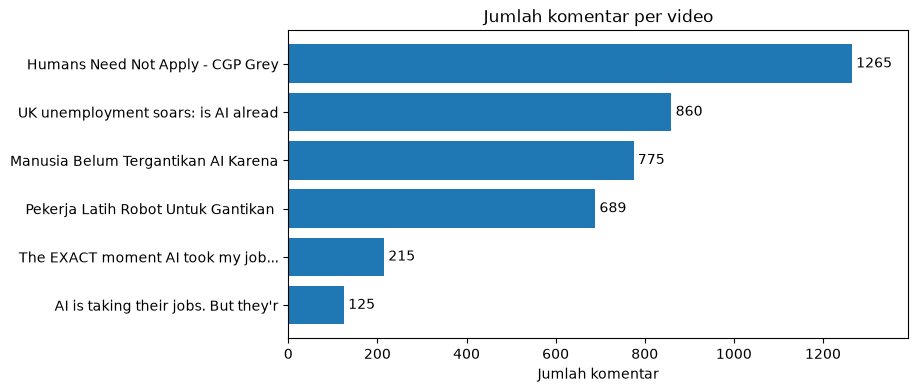

In [50]:
v = df_EDA["video_title"].value_counts().sort_values()

plt.figure(figsize=(8, 4))
batang = plt.barh(v.index.str[:35], v.values)
plt.bar_label(batang, padding=3)          # angka di ujung batang
plt.xlim(0, v.max() * 1.1)                # beri ruang supaya angka tidak terpotong
plt.title("Jumlah komentar per video")
plt.xlabel("Jumlah komentar")
plt.show()

## **4.2 Komposisi Bahasa**

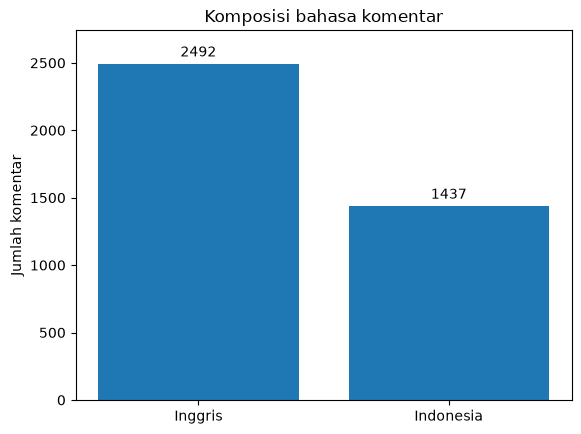

In [51]:
b = df_EDA["bahasa"].value_counts()

batang = plt.bar(b.index, b.values)
plt.bar_label(batang, padding=3)       # angka di atas batang
plt.ylim(0, b.max() * 1.1)             # beri ruang supaya angka tidak terpotong
plt.title("Komposisi bahasa komentar")
plt.ylabel("Jumlah komentar")
plt.show()

## **4.3 Bahasa per Video**

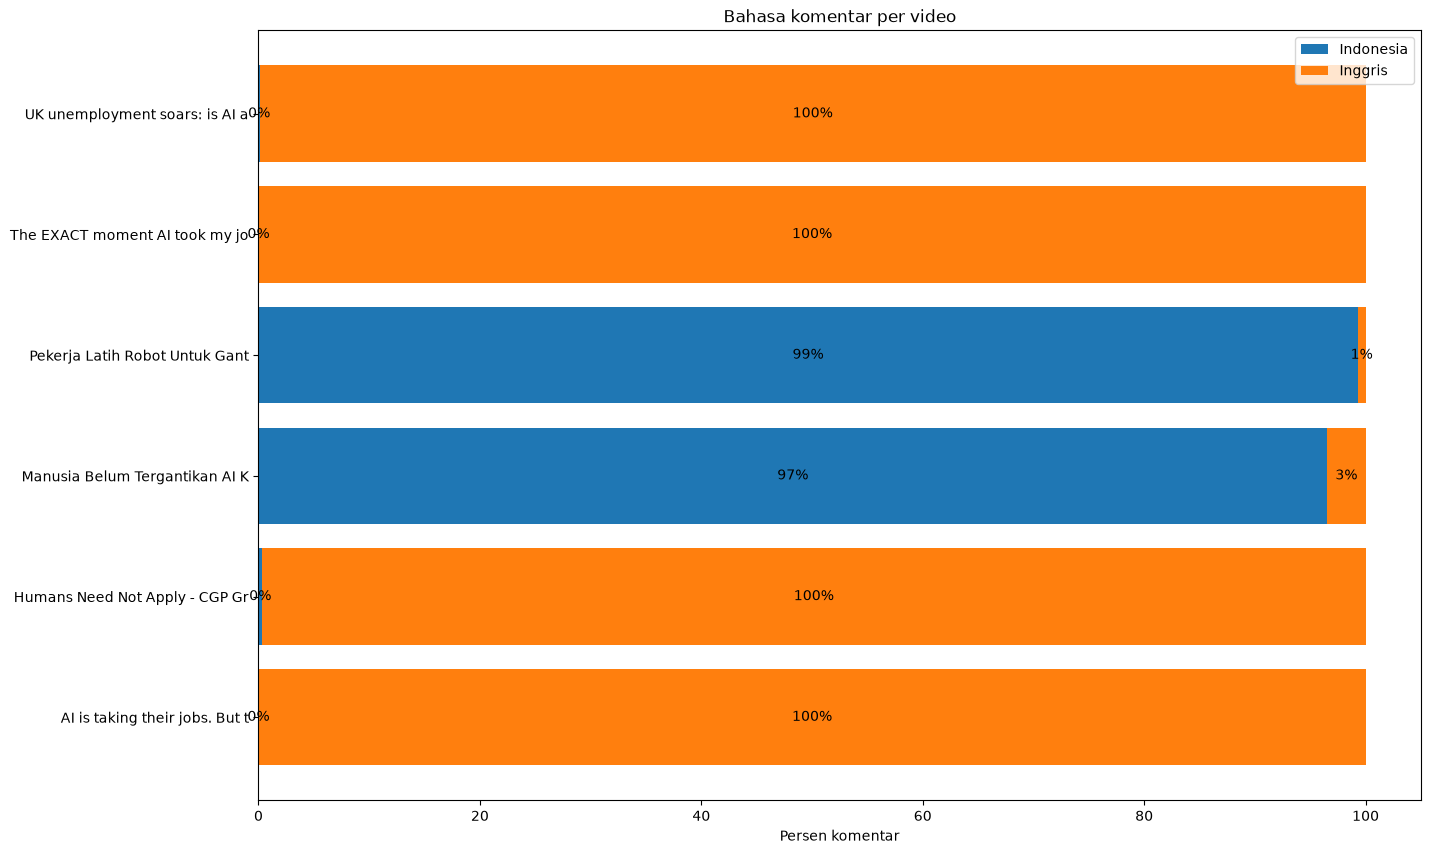

In [52]:
tabel = pd.crosstab(df_EDA["video_title"].str[:30], df_EDA["bahasa"])
persen = tabel.div(tabel.sum(axis=1), axis=0) * 100     # tiap video jadi 100%

kiri = 0
plt.figure(figsize=(15, 10))
for kolom in persen.columns:
    batang = plt.barh(persen.index, persen[kolom], left=kiri, label=kolom)
    plt.bar_label(batang, fmt="%.0f%%", label_type="center")
    kiri = kiri + persen[kolom]
plt.legend()
plt.xlabel("Persen komentar")
plt.title("Bahasa komentar per video")
plt.show()

## **4.4 Panjang Komentar**

Jumlah kata per komentar. Komentar di atas 100 kata dihitung sebagai 100 supaya grafik tetap terbaca.

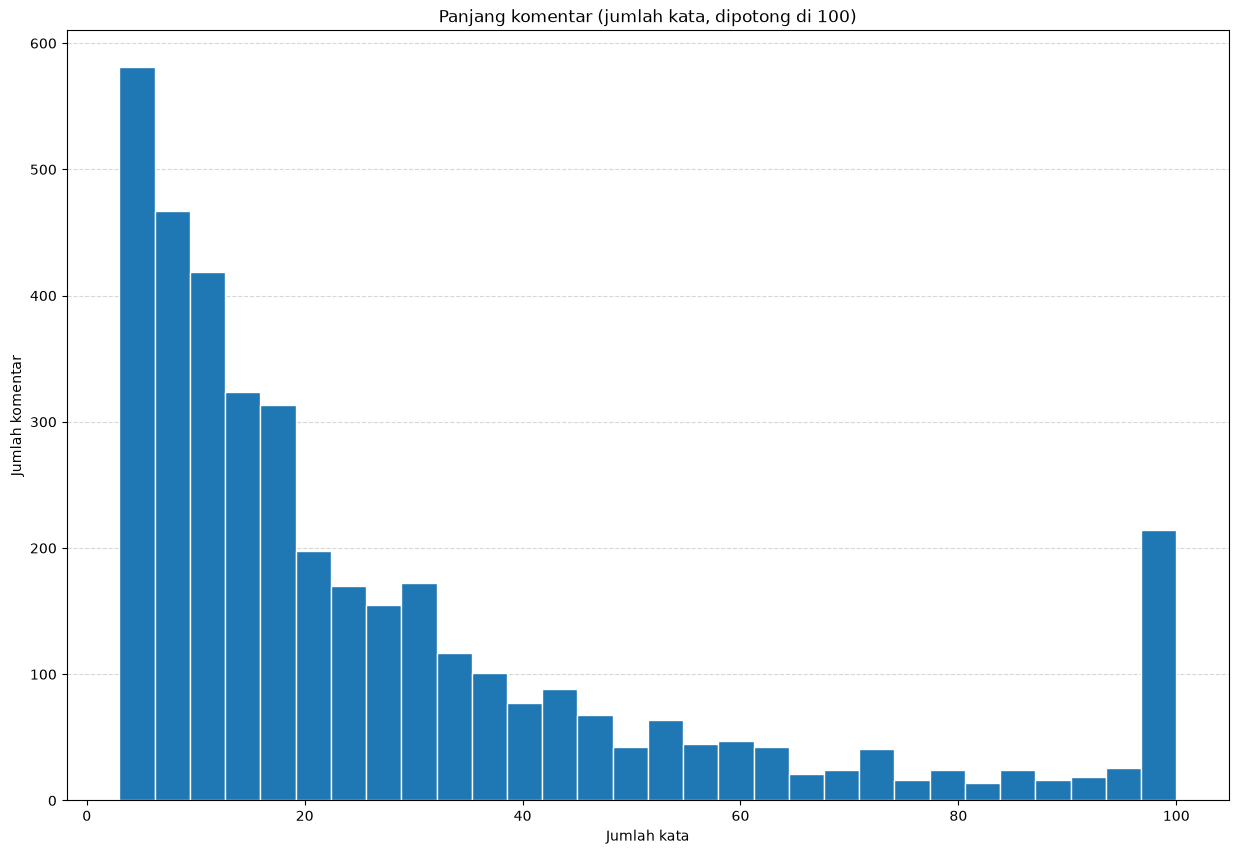

In [53]:
kata = df_EDA["comment"].str.split().str.len().clip(upper=100)

plt.figure(figsize=(15, 10))
plt.hist(kata, bins=30, edgecolor="white")
plt.grid(axis="y", linestyle="--", alpha=0.5)   # garis bantu mendatar
plt.gca().set_axisbelow(True)                   # garis di belakang batang
plt.title("Panjang komentar (jumlah kata, dipotong di 100)")
plt.xlabel("Jumlah kata")
plt.ylabel("Jumlah komentar")
plt.show()

## **4.5 Emoji dan Tanda Baca**

Jumlah komentar yang memuat emoji dan yang memuat tanda `?` atau `!`. Keduanya sering menandai emosi atau pertanyaan, dan karena itu tidak dibuang saat pembersihan teks.

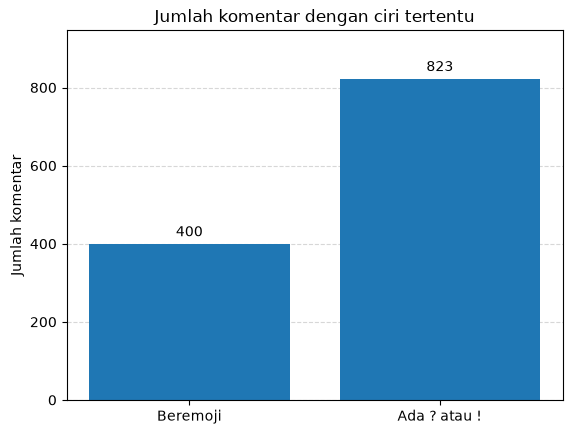

In [54]:
emoji = df_EDA["comment"].str.contains("[\U0001F300-\U0001FAFF\u2600-\u27BF]").sum()
tanda = df_EDA["comment"].str.contains(r"[?!]").sum()

batang = plt.bar(["Beremoji", "Ada ? atau !"], [emoji, tanda])
plt.bar_label(batang, padding=3)
plt.ylim(0, max(emoji, tanda) * 1.15)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)
plt.title("Jumlah komentar dengan ciri tertentu")
plt.ylabel("Jumlah komentar")
plt.show()

## **4.6 Sebaran Likes per Komentar**

Likes komentar menunjukkan seberapa banyak penonton setuju dengan komentar itu. Sebarannya sangat miring, jadi likes dikelompokkan supaya grafik tetap terbaca.

Catatan: komentar diambil dengan urutan "popular", jadi komentar yang banyak di-like lebih terwakili daripada keadaan sebenarnya.

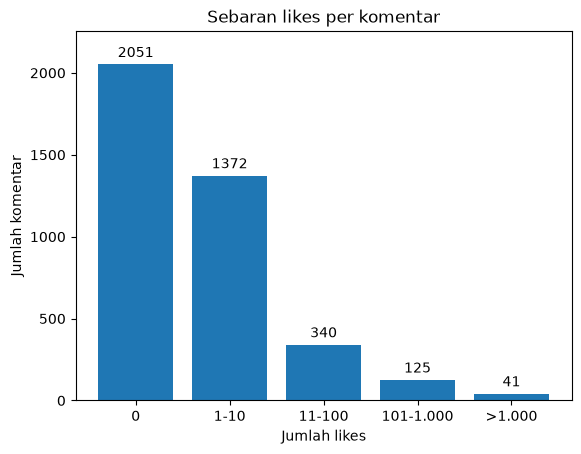

In [55]:
kelompok = pd.cut(df_EDA["likes"], bins=[-1, 0, 10, 100, 1000, float("inf")],
                  labels=["0", "1-10", "11-100", "101-1.000", ">1.000"])
k = kelompok.value_counts().sort_index()

batang = plt.bar(k.index, k.values)
plt.bar_label(batang, padding=3)
plt.ylim(0, k.max() * 1.1)
plt.title("Sebaran likes per komentar")
plt.xlabel("Jumlah likes")
plt.ylabel("Jumlah komentar")
plt.show()

**Hasil:** Lebih dari separuh komentar (52%) tidak mendapat like sama sekali, dan 87% mendapat paling banyak 10 like. Hanya 41 komentar (1%) yang mendapat lebih dari 1.000 like. Artinya, persetujuan penonton terkumpul pada segelintir komentar.

## **4.7 Komentar yang Mendapat Like per Video**

Median likes hampir selalu 0, jadi yang dibandingkan adalah persentase komentar yang mendapat minimal 1 like.

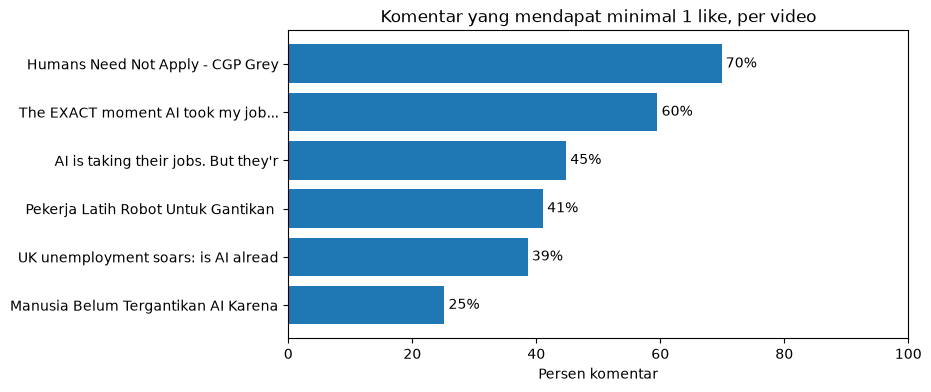

In [56]:
p = (df_EDA["likes"] > 0).groupby(df_EDA["video_title"]).mean().mul(100).sort_values()

plt.figure(figsize=(8, 4))
batang = plt.barh(p.index.str[:35], p.values)
plt.bar_label(batang, fmt="%.0f%%", padding=3)
plt.xlim(0, 100)
plt.title("Komentar yang mendapat minimal 1 like, per video")
plt.xlabel("Persen komentar")
plt.show()

**Hasil:** Komentar di video "Humans Need Not Apply" (CGP Grey) paling sering mendapat like (70%), sedangkan "Manusia Belum Tergantikan AI Karena Satu Hambatan Ini" paling jarang (25%). Angka ini juga dipengaruhi popularitas video, bukan hanya isi komentarnya.

## **4.8 Komentar yang Mendapat Like per Bahasa**

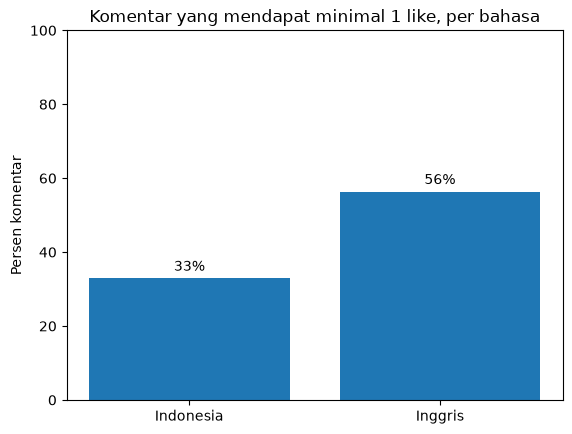

In [57]:
p = (df_EDA["likes"] > 0).groupby(df_EDA["bahasa"]).mean().mul(100)

batang = plt.bar(p.index, p.values)
plt.bar_label(batang, fmt="%.0f%%", padding=3)
plt.ylim(0, 100)
plt.title("Komentar yang mendapat minimal 1 like, per bahasa")
plt.ylabel("Persen komentar")
plt.show()

**Hasil:** Komentar bahasa Inggris lebih sering mendapat like (56%) dibanding bahasa Indonesia (33%). Sebagian besar komentar bahasa Inggris berasal dari video internasional yang jauh lebih populer, jadi perbedaan ini lebih mencerminkan jumlah penonton daripada bahasanya.

## **4.9 10 Komentar dengan Likes Terbanyak**

In [58]:
df_EDA.nlargest(10, "likes")[["comment", "likes", "video_title", "bahasa"]]

,comment,likes,video_title,bahasa
1474,"""you might think technology can't replace your job"" I'd be pretty horrified if technology started replacing unemployed peoples jobs.",31000,Humans Need Not Apply - CGP Grey,Inggris
1467,Aged like fine wine,30000,Humans Need Not Apply - CGP Grey,Inggris
1867,I'd really like an updated version of this video.,26000,Humans Need Not Apply - CGP Grey,Inggris
1478,"""The human brain is the most complicated machine, perhaps in the whole universe."" - Human Brain",24000,Humans Need Not Apply - CGP Grey,Inggris
1869,"So you think a bot can take my job? The joke's on you, I don't have a job!",19000,Humans Need Not Apply - CGP Grey,Inggris
1470,"This was 8 years ago, now with the sudden rise of AI music, AI art, AI video, ChatGPT, and so on... that's crazy...",14000,Humans Need Not Apply - CGP Grey,Inggris
1880,New goal: Make it to retirement without being replaced,14000,Humans Need Not Apply - CGP Grey,Inggris
1466,This wouldn't be scary if we lived in a world where being unemployed didn't mean loss of livelihood,13000,Humans Need Not Apply - CGP Grey,Inggris
1464,I was thinking this video was getting out of date… then AI art and language models arrived and I am more concerned about this topic than...,11000,Humans Need Not Apply - CGP Grey,Inggris
1483,"Those darn automation engineers, taking over everyone's jobs. At least I'm safe looks at degree in robotics ... looks at robots that tea...",9800,Humans Need Not Apply - CGP Grey,Inggris


**Hasil:** Kesepuluh komentar teratas semuanya berasal dari video CGP Grey (bahasa Inggris), dengan 9.800 sampai 31.000 like. Isinya didominasi candaan dan kekhawatiran soal pekerjaan yang digantikan teknologi, misalnya "New goal: Make it to retirement without being replaced" (14.000 like).

# **5. Pelabelan (Labeling)**

Komentar belum punya label, jadi label dibuat otomatis dengan model *pre-trained* lalu dinilai terhadap gold set (label manual). Yang dinilai adalah **sikap penulis terhadap AI yang menggantikan pekerjaan manusia**:

| Label | Arti |
|---|---|
| positif | tidak merasa terancam: optimis, mendukung AI, mengajak beradaptasi, atau membantah bahwa AI akan menggantikan manusia |
| negatif | merasa terancam: takut kehilangan pekerjaan atau memperingatkan bahaya AI bagi manusia |
| netral | membahas AI, robot, otomasi, atau pekerjaan tanpa memihak, termasuk candaan |
| tidak relevan | tidak membahas AI, robot, otomasi, atau pekerjaan |

Dua model dibandingkan, masing-masing dengan cara terbaik yang bisa dilakukannya:

| Konfigurasi | Model | Berjalan di | Cara |
|---|---|---|---|
| `Nemotron \| few-shot` | Nemotron 3 Ultra, LLM 550 miliar parameter | server NVIDIA lewat API | panduan + contoh berlabel |
| `mDeBERTa \| zero-shot` | mDeBERTa-v3 multibahasa, model NLI ±280 juta parameter | lokal, GPU RTX 4050 | hipotesis tanpa contoh (NLI tidak bisa diberi contoh) |

Alurnya: pilih konfigurasi dengan macro-F1 tertinggi pada **dev** (50 komentar) → uji **sekali** pada **test** (100 komentar) → labeli seluruh data bersih.

## **5.1 Persiapan**

- API key NVIDIA dibaca dari Colab Secrets (di Colab) atau dari file `.env` / environment variable `NVIDIA_API_KEY_NEMOTRON_3_ULTRA` (di VSCode). Isi key tidak pernah ditulis atau ditampilkan di notebook.
- `MODEL_NEMOTRON` dipanggil lewat API NVIDIA, sedangkan `MODEL_MDEBERTA` diunduh dari HuggingFace lalu dijalankan lokal.

In [59]:
# Deteksi Google Colab vs VSCode untuk pengambilan API Key
api_key = None
if os.path.exists('/content'):
    try:
        from google.colab import userdata
        api_key = userdata.get("NVIDIA_API_KEY_NEMOTRON_3_ULTRA")
    except Exception as e:
        print(f"Catatan: Gagal memuat API Key dari Colab userdata: {e}")

if not api_key:
    # VSCode / lokal: baca dari file .env di root project (tidak ikut ke GitHub) atau environment variable.
    # Jangan tulis API key langsung di notebook ini.
    load_dotenv(find_dotenv(usecwd=True))
    api_key = os.environ.get("NVIDIA_API_KEY_NEMOTRON_3_ULTRA", "").strip()

if not api_key.startswith("nvapi-"):
    raise ValueError("API key NVIDIA belum terbaca. Isi NVIDIA_API_KEY_NEMOTRON_3_ULTRA di file .env "
                     "(root project) lalu jalankan ulang sel ini.")
print("API key NVIDIA terbaca ✅")      # isi key sengaja tidak ditampilkan

client = OpenAI(
    base_url="https://integrate.api.nvidia.com/v1",
    api_key=api_key,
)

MODEL_NEMOTRON = "nvidia/nemotron-3-ultra-550b-a55b"
MODEL_MDEBERTA = "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7"   # NLI multibahasa, dijalankan lokal
urutan = ["positif", "negatif", "netral", "tidak relevan"]


API key NVIDIA terbaca ✅


## **5.2 Gold Set**

Gold set berisi 150 komentar yang dilabeli manual. **Dev** (50 komentar terakhir) dipakai untuk membandingkan kedua konfigurasi, sedangkan **test** (100 komentar pertama) hanya dipakai sekali di akhir untuk melaporkan kinerja pelabel yang terpilih.

In [60]:
# Deteksi lokasi pengambilan dataset gold set (Google Colab vs VSCode / Lokal)
if os.path.exists('/content/gold_set_final.csv'):
    # Google Colab
    path_gold = '/content/gold_set_final.csv'
elif os.path.exists('../../datasets/gold_set_final.csv'):
    # VSCode (dari folder notebook)
    path_gold = '../../datasets/gold_set_final.csv'
elif os.path.exists('datasets/gold_set_final.csv'):
    # VSCode (dari root project)
    path_gold = 'datasets/gold_set_final.csv'
else:
    path_gold = 'gold_set_final.csv'

g = pd.read_csv(path_gold)
print(f"Gold set dimuat dari: {path_gold} ({len(g)} baris)")

test = g.iloc[:100].reset_index(drop=True)
dev = g.iloc[100:].reset_index(drop=True)

print("test:", len(test), "| dev:", len(dev))
g["label"].value_counts()


Gold set dimuat dari: ../../datasets/gold_set_final.csv (150 baris)
test: 100 | dev: 50


label
tidak relevan    53
netral           40
negatif          31
positif          26
Name: count, dtype: int64

## **5.3 Panduan, Contoh, dan Hipotesis**

- `PANDUAN`: aturan pelabelan untuk Nemotron (apakah penulis melihat AI menggantikan pekerjaan sebagai ancaman).
- `CONTOH2`: contoh berlabel yang diambil dari **luar** gold set. Digabung dengan panduan menjadi `FEWSHOT`.
- `HIPOTESIS_EN`: untuk mDeBERTa. Tiap label diwakili satu frasa yang disisipkan ke templat, misalnya *"The author of this comment fears AI will replace human jobs."* Frasa sengaja dibuat pendek karena model NLI bekerja lebih baik dengan hipotesis singkat.
- `pengaturan`: daftar kedua konfigurasi yang dibandingkan.

In [61]:
PANDUAN = """Tugas: tentukan sikap komentar YouTube terhadap isu AI yang menggantikan pekerjaan manusia.

Pertanyaan utama: penulis melihat AI menggantikan pekerjaan sebagai ancaman atau tidak?

Pilih satu label:
- positif: tidak merasa terancam, optimis, mendukung AI, mengajak belajar dan beradaptasi, atau berharap AI dipakai untuk meringankan pekerjaan. Termasuk komentar yang menunjukkan kelemahan AI sehingga tidak takut, atau membantah bahwa AI akan menggantikan manusia.
- negatif: merasa terancam, takut kehilangan pekerjaan, atau memperingatkan bahaya AI bagi manusia
- netral: membahas AI, robot, otomasi, atau pekerjaan tanpa memihak, termasuk candaan tentang kemampuan AI atau robot
- tidak relevan: tidak membahas AI, robot, otomasi, atau pekerjaan

Jawab satu label saja, tanpa penjelasan."""

In [62]:
CONTOH = """Contoh:
Komentar: I mean, a robot doesnt need money, doesn't have emotions (yet), so yeah, of course a robot boss would be the best bos
Label: netral

Komentar: Hmm.. Bisa ngga ya AI menggantikan seluruh pejabat di pemerintahan Konoha dari kepala sampai kaki..?
Label: netral

Komentar: Meanwhile in konoha, gen-z pilih2 atau bahkan nolak kerjaan Krn gaji kecil..😊 .. btw..gw masih dukung buat yg mau kabur ke LN, kalau bisa secepatnya lah kalian pada kabur 😁
Label: tidak relevan

Komentar: in fact most 'accidents' aren't even accidents at all. Most of them are due to the way that street was designed, if the semaphores are smart of not, how strict are regulations etc, i.e.: they are life sentences because depending on the way a street was designed theyre unavoiadable (im looking at you american stroads with cars speeding inside cities
Label: tidak relevan

Komentar: bahkan alam aja sudah berusaha melindungi manusia dari kepunahan dengan cara menghalangi/menghambat energi sebanyak itu untuk bisa digunakan pengembangan AI
Label: negatif

Komentar: Pull the fucking plug. Nobody wants AI
Label: negatif

Komentar: As an AI engineer I’ll say, these systems are only as good as the data and governance behind them, and most companies are skipping that part. Leaders are rushing to plug in third party tools, trusting outputs they don’t fully understand, and calling it transformation. Sure, you see efficiency at the individual level. But at the enterprise level? Not much. What I see is technical debt building fast. People are spinning up agents with no lifecycle plan, no monitoring, no real ownership. That doesn’t disappear. It compounds. AI absolutely cuts lower end roles and creates efficiency. But it also increases reliance on high end expertise and long term maintenance. The cost doesn’t go away, it just shifts up the chain. There’s no free lunch.
Label: positif

Komentar: Konten ini mengatakan betapa CERDAS DAN MENAKUTKANNYA AI. Kecerdasan AI setara dokto matematika Tapi LUCUNYA dia mengatakan satu satunya masalah AI sekarang adalah : energi . AI butuh energi yang besar. Apakah AI tidak bisa MEMAKAI SEGALA KECERDASAN YANG DI GEMABR GEMBORKA ITU MENCONTEK CARA KERJA OTAK MANUSIA DALAM EFESIENSI ENERGI JADI MASALAH ENERGI YANG BELUM TERSELESAIKAN: ITU KONTRADIKSI DENGAN MENGATAKAN GEMBAR GEMBOR KECERDASAN AI
Label: positif"""

In [63]:
CONTOH2 = CONTOH + """

Komentar: Ada quantum computing. Kalau AI digabung dgn quantum computing?
Label: netral

Komentar: Bang bahkan baru² ini di Indonesia udh ada video tukang martabak yg dipakein kamera di topinya buat ai pelajarin
Label: netral"""

FEWSHOT = PANDUAN + "\n\n" + CONTOH2

In [64]:
# Hipotesis mDeBERTa (NLI zero-shot): (templat, {label: frasa})
HIPOTESIS_EN = ("The author of this comment {}.", {
    "positif": "is optimistic and does not feel threatened by AI",
    "negatif": "fears AI will replace human jobs",
    "netral": "talks about AI or jobs without taking a side",
    "tidak relevan": "does not talk about AI, robots, automation, or jobs",
})

In [65]:
# Dua konfigurasi yang dibandingkan: nama -> (panduan atau hipotesis, model)
pengaturan = {
    "Nemotron | few-shot": (FEWSHOT, MODEL_NEMOTRON),
    "mDeBERTa | zero-shot": (HIPOTESIS_EN, MODEL_MDEBERTA),
}

## **5.4 Fungsi Pelabelan dan Penilaian**

**Nemotron (lewat API)**
- `tanya_llm`: mengirim satu komentar dan mengembalikan jawaban mentah. Kalau kena limit (error 429), koneksi putus atau *timeout* (60 detik), atau server NVIDIA error (5xx), fungsi menunggu lalu mencoba lagi **tanpa batas** dengan jeda yang naik bertahap (30, 60, 120, ... paling lama 300 detik). Error yang tidak sembuh dengan menunggu (misalnya API key salah) langsung dihentikan supaya ketahuan.
- `ambil_label` mengambil label dari jawaban, `label_llm` menggabungkan keduanya. Jawaban tanpa label yang dikenali menjadi "tidak relevan".
- `label_berurutan`: melabeli banyak komentar satu per satu dengan jeda `JEDA_PERMINTAAN` = 3 detik antar permintaan (paling banyak 20 per menit, di bawah limit NVIDIA). Ditambah waktu jawaban Nemotron (sekitar 1,3 detik), satu komentar butuh sekitar 4,3 detik, sehingga 50 komentar dev selesai sekitar 3,5 menit.
- Mode berpikir Nemotron dimatikan, `temperature=0`, dan `seed=SEED`, supaya jawabannya sekonsisten mungkin.

**mDeBERTa (lokal)**
- `muat_nli`: memuat model sekali saja, di GPU kalau PyTorch CUDA tersedia.
- `label_nli`: melabeli banyak komentar dengan hipotesis yang dipilih. Label = frasa hipotesis dengan skor *entailment* tertinggi.

**Untuk keduanya**
- `label_banyak`: satu pintu yang memanggil `label_nli` atau `label_berurutan` sesuai model. Dipakai di 5.5 sampai 5.8.
- `uji`, `tampilkan_matrix`, `grafik_skor`: menilai satu konfigurasi pada dev (macro-F1 dan classification report), menggambar confusion matrix, dan membandingkan skor. Skor disimpan di `skor`; menjalankan ulang sel fungsi tidak menghapus skor yang sudah ada.

In [66]:
# Retry diatur sendiri di tanya_llm, jadi retry bawaan library dimatikan; timeout supaya tidak menggantung selamanya
client = client.with_options(timeout=60, max_retries=0)

LABEL_VALID = ["tidak relevan", "positif", "negatif", "netral"]


def tanya_llm(komentar, panduan, model):
    """Kirim satu komentar ke LLM dan kembalikan jawaban mentahnya (huruf kecil)."""
    tambahan = {}
    if "nemotron" in model:
        tambahan = {"chat_template_kwargs": {"enable_thinking": False}}

    coba = 0
    while True:                  # tanpa batas percobaan: tunggu lalu ulangi sampai berhasil
        try:
            jawaban = client.chat.completions.create(
                model=model,
                messages=[{"role": "system", "content": panduan},
                          {"role": "user", "content": f"Komentar: {komentar}\nLabel:"}],
                temperature=0,
                seed=SEED,
                max_tokens=10,
                extra_body=tambahan,
            )
            return (jawaban.choices[0].message.content or "").strip().lower()
        except (RateLimitError, APIConnectionError, InternalServerError) as e:
            jeda = min(30 * 2 ** coba, 300)      # 30, 60, 120, 240, 300, 300, ...
            coba += 1
            print(f"{type(e).__name__} (percobaan ke-{coba}), tunggu {jeda} detik lalu coba lagi...")
            time.sleep(jeda)


def ambil_label(hasil):
    """Ambil label dari jawaban LLM; None kalau tidak ada label yang dikenali."""
    for lab in LABEL_VALID:
        if lab in hasil:
            return lab
    return None


def label_llm(komentar, panduan, model):
    return ambil_label(tanya_llm(komentar, panduan, model)) or "tidak relevan"


JEDA_PERMINTAAN = 3              # detik jeda antar permintaan (paling banyak 20 per menit, di bawah limit NVIDIA)


def label_berurutan(daftar_komentar, panduan, model):
    """Labeli komentar satu per satu dengan LLM; urutan hasil sama dengan urutan masukan."""
    waktu_mulai = time.time()
    hasil = []
    for komentar in daftar_komentar:
        hasil.append(label_llm(komentar, panduan, model))
        time.sleep(JEDA_PERMINTAAN)
    print(f"{len(hasil)} komentar dilabeli dalam {(time.time() - waktu_mulai) / 60:.1f} menit")
    return hasil


_nli = {}


def muat_nli():
    """Muat mDeBERTa sekali saja; pakai GPU kalau PyTorch CUDA tersedia."""
    if "pipa" not in _nli:
        perangkat = 0 if torch.cuda.is_available() else -1
        nama_perangkat = torch.cuda.get_device_name(0) if perangkat == 0 else "CPU (GPU CUDA tidak terdeteksi, jauh lebih lambat)"
        print("mDeBERTa dijalankan di:", nama_perangkat)
        _nli["pipa"] = pipeline("zero-shot-classification", model=MODEL_MDEBERTA, device=perangkat)
    return _nli["pipa"]


def label_nli(daftar_komentar, hipotesis, ukuran_batch=32):
    """Labeli komentar dengan mDeBERTa: label = frasa hipotesis dengan skor entailment tertinggi."""
    templat, frasa = hipotesis
    balik = {v: k for k, v in frasa.items()}
    waktu_mulai = time.time()
    hasil = muat_nli()(list(daftar_komentar), candidate_labels=list(frasa.values()),
                       hypothesis_template=templat, multi_label=False, batch_size=ukuran_batch)
    if isinstance(hasil, dict):          # satu komentar: pipeline mengembalikan dict, bukan list
        hasil = [hasil]
    print(f"{len(hasil)} komentar dilabeli mDeBERTa dalam {(time.time() - waktu_mulai) / 60:.1f} menit")
    return [balik[h["labels"][0]] for h in hasil]


def label_banyak(daftar_komentar, panduan, model):
    """Satu pintu untuk semua konfigurasi: mDeBERTa lokal atau LLM lewat API."""
    if model == MODEL_MDEBERTA:
        return label_nli(daftar_komentar, panduan)
    return label_berurutan(daftar_komentar, panduan, model)

In [67]:
# Kalau sel ini dijalankan ulang, skor yang sudah ada tidak hilang
skor = globals().get("skor", {})
semua_prediksi = globals().get("semua_prediksi", {})

def uji(nama):
    panduan, model = pengaturan[nama]
    prediksi = label_banyak(dev["comment"].tolist(), panduan, model)
    skor[nama] = round(f1_score(dev["label"], prediksi, average="macro"), 3)
    semua_prediksi[nama] = prediksi
    print(nama, "| macro-F1 =", skor[nama])
    print(classification_report(dev["label"], prediksi, zero_division=0))


def tampilkan_matrix(nama):
    ConfusionMatrixDisplay.from_predictions(dev["label"], semua_prediksi[nama], labels=urutan, cmap="Blues")
    plt.title(f"Confusion matrix (dev): {nama}")
    plt.xlabel("Prediksi LLM")
    plt.ylabel("Label manual")
    plt.show()


def grafik_skor(daftar_nama, judul):
    nilai = [skor[n] for n in daftar_nama]
    plt.figure(figsize=(8, 4))
    batang = plt.bar(daftar_nama, nilai)
    plt.bar_label(batang, fmt="%.3f", padding=3)
    plt.ylim(0, 1)
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.gca().set_axisbelow(True)
    plt.title(judul)
    plt.ylabel("macro-F1 (dev)")
    plt.show()

## **5.5 Nemotron 3 Ultra (Few-shot)**

LLM generatif dengan 550 miliar parameter (55 miliar aktif per token) yang dipanggil lewat API NVIDIA. Model diberi `PANDUAN` beserta contoh berlabel (few-shot), lalu dinilai pada dev.

### **1. Few-shot**

In [ ]:
uji("Nemotron | few-shot")

RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...


### **2. Confusion matrix few-shot**

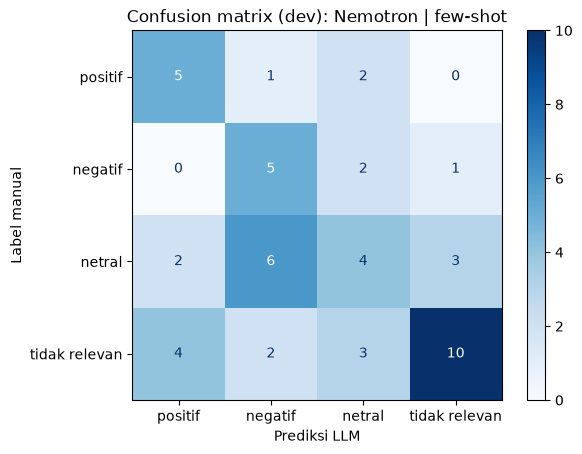

In [69]:
tampilkan_matrix("Nemotron | few-shot")

## **5.6 mDeBERTa-v3 Multibahasa (Zero-shot)**

mDeBERTa berjalan di laptop sendiri, jadi tidak ada limit, *timeout*, maupun biaya.

- **Model:** `MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7`, sekitar 280 juta parameter, dilatih untuk *Natural Language Inference* (NLI) di lebih dari 100 bahasa, termasuk Indonesia dan Inggris.
- **Cara kerja:** tiap komentar dipasangkan dengan empat kalimat hipotesis (satu per label). Model menilai seberapa besar komentar *mendukung* (entailment) tiap hipotesis, lalu hipotesis dengan skor tertinggi menjadi labelnya.
- **Kenapa zero-shot:** model NLI tidak bisa diberi contoh seperti LLM, sehingga konteks hanya masuk lewat rumusan hipotesis (`HIPOTESIS_EN`).
- **GPU:** model otomatis memakai RTX 4050 bila PyTorch versi CUDA terpasang. Unduhan pertama sekitar 1,1 GB ke cache HuggingFace.

### **3. Memuat mDeBERTa**

In [70]:
print("PyTorch:", torch.__version__, "| CUDA tersedia:", torch.cuda.is_available())
muat_nli();

PyTorch: 2.11.0+cu128 | CUDA tersedia: True
mDeBERTa dijalankan di: NVIDIA GeForce RTX 4050 Laptop GPU


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

### **4. Zero-shot**

In [71]:
uji("mDeBERTa | zero-shot")

50 komentar dilabeli mDeBERTa dalam 0.0 menit
mDeBERTa | zero-shot | macro-F1 = 0.313
               precision    recall  f1-score   support

      negatif       0.17      0.25      0.20         8
       netral       0.38      0.20      0.26        15
      positif       0.33      0.12      0.18         8
tidak relevan       0.52      0.74      0.61        19

     accuracy                           0.40        50
    macro avg       0.35      0.33      0.31        50
 weighted avg       0.39      0.40      0.37        50



### **5. Confusion matrix zero-shot**

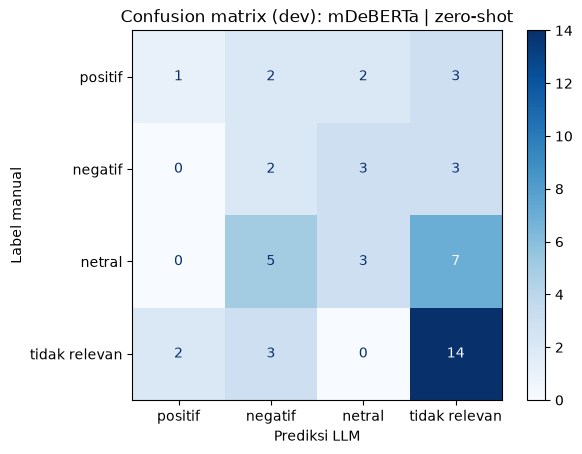

In [72]:
tampilkan_matrix("mDeBERTa | zero-shot")

## **5.7 Perbandingan dan Pemilihan Konfigurasi**

### **6. Bandingkan kedua konfigurasi**

Konfigurasi dengan macro-F1 dev tertinggi dipilih otomatis lalu dipakai untuk melabeli seluruh data.

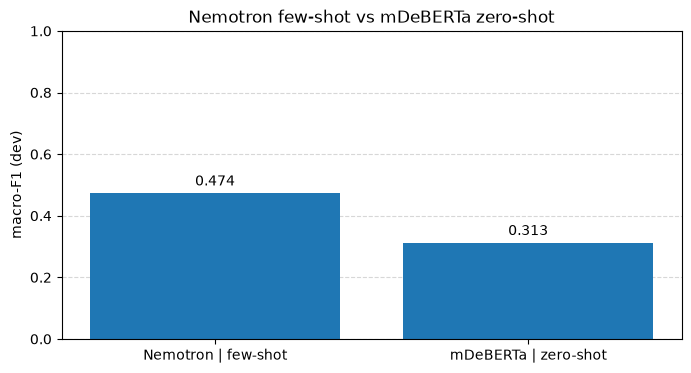

In [73]:
grafik_skor(list(pengaturan.keys()), "Nemotron few-shot vs mDeBERTa zero-shot")

In [74]:
terbaik = max(pengaturan, key=lambda nama: skor[nama])   # hanya konfigurasi di pengaturan
# terbaik = "Nemotron | few-shot"     # aktifkan baris ini kalau ingin memilih manual

panduan_terbaik, model_terbaik = pengaturan[terbaik]
print("Konfigurasi terpilih:", terbaik, "| macro-F1 dev =", skor[terbaik])

Konfigurasi terpilih: Nemotron | few-shot | macro-F1 dev = 0.474


### **7. Uji sekali pada data test**

Data test belum pernah dipakai saat memilih konfigurasi, sehingga angka ini yang dilaporkan sebagai kinerja pelabel.

RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-2), tunggu 60 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-2), tunggu 60 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-2), tunggu 60 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lag

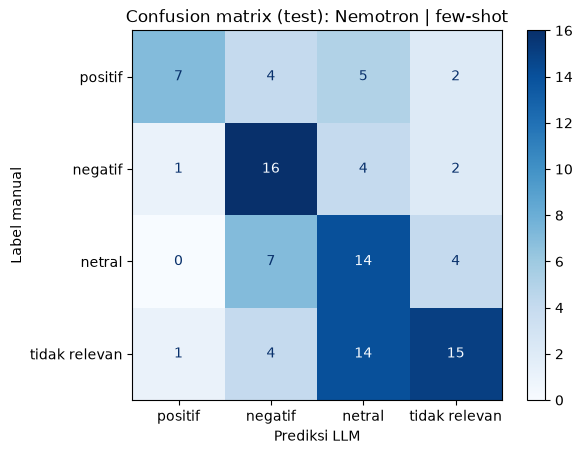

In [75]:
prediksi_test = label_banyak(test["comment"].tolist(), panduan_terbaik, model_terbaik)

print(terbaik, "| macro-F1 test =", round(f1_score(test["label"], prediksi_test, average="macro"), 3))
print(classification_report(test["label"], prediksi_test, zero_division=0))

ConfusionMatrixDisplay.from_predictions(test["label"], prediksi_test, labels=urutan, cmap="Blues")
plt.title(f"Confusion matrix (test): {terbaik}")
plt.xlabel("Prediksi LLM")
plt.ylabel("Label manual")
plt.show()

## **5.8 Pelabelan Seluruh Data**

Seluruh komentar di `youtube_comments_clean_EDA.csv` (3.929 komentar) dilabeli dengan konfigurasi terpilih dalam sekali jalan. Sel ini cukup dijalankan satu kali lalu dibiarkan sampai selesai.

- **Konfigurasi:** `KONFIGURASI` otomatis memakai `terbaik` dari 5.7. Kalau runtime sempat restart, jalankan sel 1 dan 5.1 sampai 5.4, lalu sel ini; nilai cadangan `"Nemotron | few-shot"` yang dipakai (ubah kalau pilihanmu lain).
- **Kalau Nemotron terpilih:** komentar dikirim satu per satu dengan jeda `JEDA_PERMINTAAN` = 3 detik, sekitar 4,3 detik per komentar atau **sekitar 4 jam 40 menit** untuk seluruh data bila jarang kena limit. Kalau masih sering kena 429, naikkan `JEDA_PERMINTAAN` (misalnya ke 4).
- **Kalau mDeBERTa terpilih:** komentar dilabeli lokal per 256 komentar, beberapa menit di GPU.
- **Checkpoint setiap hasil:** tiap label langsung ditulis ke `label_sementara.csv` bersama nomor baris, isi komentar, dan jawaban mentah. Kalau proses terputus, jalankan sel ini lagi dan pelabelan berlanjut dari yang belum. Isi komentar dicocokkan dengan data, jadi label tidak mungkin tergeser ke komentar yang salah.
- **Ganti konfigurasi:** hapus atau ganti nama `label_sementara.csv` lebih dulu, supaya label dari dua pelabel tidak tercampur.

In [76]:
# ===== Pengaturan =====
KONFIGURASI = globals().get("terbaik", "Nemotron | few-shot")   # cadangan bila 5.5-5.7 tidak dijalankan ulang
JEDA_PERMINTAAN = 3          # detik jeda antar permintaan Nemotron (paling banyak 20 per menit)

panduan_pakai, model_pakai = pengaturan[KONFIGURASI]
print("Konfigurasi pelabel:", KONFIGURASI)

# Deteksi lokasi pengambilan dataset untuk pelabelan (Google Colab vs VSCode / Lokal)
if os.path.exists('/content/youtube_comments_clean_EDA.csv'):
    # Google Colab
    path_clean = '/content/youtube_comments_clean_EDA.csv'
    FILE_SEMENTARA = '/content/label_sementara.csv'
elif os.path.exists('../../datasets/youtube_comments_clean_EDA.csv'):
    # VSCode (dari folder notebook)
    path_clean = '../../datasets/youtube_comments_clean_EDA.csv'
    FILE_SEMENTARA = '../../datasets/label_sementara.csv'
elif os.path.exists('../../datasets/youtube_comments_clean.csv'):
    # Fallback ke dataset clean yang ada di folder datasets
    path_clean = '../../datasets/youtube_comments_clean.csv'
    FILE_SEMENTARA = '../../datasets/label_sementara.csv'
elif os.path.exists('datasets/youtube_comments_clean_EDA.csv'):
    # VSCode (dari root project)
    path_clean = 'datasets/youtube_comments_clean_EDA.csv'
    FILE_SEMENTARA = 'datasets/label_sementara.csv'
elif os.path.exists('datasets/youtube_comments_clean.csv'):
    path_clean = 'datasets/youtube_comments_clean.csv'
    FILE_SEMENTARA = 'datasets/label_sementara.csv'
else:
    path_clean = 'youtube_comments_clean_EDA.csv'
    FILE_SEMENTARA = 'label_sementara.csv'

data = pd.read_csv(path_clean)
komentar_data = data["comment"].fillna("").astype(str)
print(f"Data pelabelan dimuat dari: {path_clean} ({len(data)} baris)")

KOLOM_CHECKPOINT = ["id", "comment", "label", "jawaban_mentah"]


def baca_checkpoint():
    """Baca checkpoint dan pastikan setiap label menempel pada komentar yang benar."""
    if not os.path.exists(FILE_SEMENTARA):
        return pd.DataFrame(columns=KOLOM_CHECKPOINT)
    cp = pd.read_csv(FILE_SEMENTARA, dtype=str, keep_default_na=False)
    if "id" not in cp.columns:
        # Format lama (hanya kolom label, berurutan dari baris 0): ubah ke format baru
        cp = pd.DataFrame({"id": range(len(cp)), "comment": komentar_data.iloc[:len(cp)].values,
                           "label": cp["label"].values, "jawaban_mentah": ""})
        cp.to_csv(FILE_SEMENTARA, index=False)
        print("Checkpoint format lama diubah ke format baru.")
    cp["id"] = cp["id"].astype(int)
    cp = cp.drop_duplicates("id", keep="last").set_index("id").sort_index()
    beda = cp.index[cp["comment"].values != komentar_data.loc[cp.index].values]
    if len(beda) > 0:
        raise ValueError(f"{len(beda)} komentar di {FILE_SEMENTARA} tidak cocok dengan data (contoh id {list(beda[:5])}). "
                         "Data bersih sudah berubah sejak checkpoint dibuat; hapus/ganti nama checkpoint lalu ulangi.")
    return cp


# Lanjutkan dari hasil sebelumnya kalau ada
checkpoint = baca_checkpoint()
sisa = [i for i in range(len(data)) if i not in checkpoint.index]
print(f"Sudah dilabeli: {len(checkpoint)} | sisa: {len(sisa)} dari {len(data)}")

if sisa:
    waktu_mulai = time.time()
    file_baru = not os.path.exists(FILE_SEMENTARA)
    with open(FILE_SEMENTARA, "a", newline="", encoding="utf-8") as f:
        tulis = csv.writer(f)
        if file_baru:
            tulis.writerow(KOLOM_CHECKPOINT)

        if model_pakai == MODEL_MDEBERTA:
            # mDeBERTa berjalan lokal tanpa limit: dilabeli per 256 komentar
            for awal in range(0, len(sisa), 256):
                potongan = sisa[awal:awal + 256]
                for i, label in zip(potongan, label_nli(komentar_data.iloc[potongan].tolist(), panduan_pakai)):
                    tulis.writerow([i, komentar_data.iloc[i], label, label])
                f.flush()
                print(f"{len(checkpoint) + awal + len(potongan)} / {len(data)} selesai")
        else:
            # Nemotron lewat API: satu per satu, setiap hasil langsung disimpan
            for n, i in enumerate(sisa, 1):
                mentah = tanya_llm(komentar_data.iloc[i], panduan_pakai, model_pakai)
                tulis.writerow([i, komentar_data.iloc[i], ambil_label(mentah) or "tidak relevan", mentah])
                f.flush()                           # langsung tersimpan, tidak ada yang hilang kalau terputus
                time.sleep(JEDA_PERMINTAAN)
                if n % 50 == 0 or n == len(sisa):
                    lewat = time.time() - waktu_mulai
                    perkiraan = lewat / n * (len(sisa) - n)
                    print(f"{len(checkpoint) + n} / {len(data)} selesai | "
                          f"berjalan {lewat / 60:.0f} menit | perkiraan sisa {perkiraan / 60:.0f} menit")

checkpoint = baca_checkpoint()
assert len(checkpoint) == len(data), "Masih ada komentar yang belum dilabeli; jalankan sel ini lagi."
label_semua = checkpoint.loc[range(len(data)), "label"].tolist()

tak_terbaca = (checkpoint["jawaban_mentah"] != "") & checkpoint["jawaban_mentah"].map(ambil_label).isna()
print("Selesai:", len(label_semua), "komentar")
print("Jawaban LLM tanpa label yang dikenali (otomatis jadi 'tidak relevan'):", int(tak_terbaca.sum()))

Konfigurasi pelabel: Nemotron | few-shot
Data pelabelan dimuat dari: ../../datasets/youtube_comments_clean_EDA.csv (3929 baris)
Sudah dilabeli: 2881 | sisa: 1048 dari 3929
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-2), tunggu 60 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaan ke-1), tunggu 30 detik lalu coba lagi...
RateLimitError (percobaa

## **5.9 Sebaran Label dan Menyimpan Hasil**

Label digabungkan ke data, sebarannya ditampilkan, lalu disimpan sebagai `youtube_comments_gold.csv` di folder `datasets`. File ini menjadi masukan notebook klasifikasi (Bab 6).

In [77]:
data["label"] = label_semua
data["label"].value_counts()

label
tidak relevan    1091
negatif          1039
netral           1005
positif           794
Name: count, dtype: int64

In [78]:
# Simpan hasil pelabelan akhir (Google Colab vs VSCode / Lokal)
if os.path.exists('/content'):
    # Google Colab
    output_path = '/content/youtube_comments_gold.csv'
    data.to_csv(output_path, index=False)
    print(f"Hasil pelabelan disimpan di Colab: {output_path}")
    try:
        from google.colab import files
        files.download(output_path)
    except Exception as e:
        print(f"Download otomatis browser dilewati: {e}")
else:
    # VSCode / Lingkungan Lokal: simpan ke folder datasets
    if os.path.exists('../../datasets'):
        output_path = '../../datasets/youtube_comments_gold.csv'
    elif os.path.exists('datasets'):
        output_path = 'datasets/youtube_comments_gold.csv'
    else:
        output_path = 'youtube_comments_gold.csv'

    data.to_csv(output_path, index=False)
    print(f"Hasil pelabelan berhasil disimpan di folder datasets: {output_path}")


Hasil pelabelan berhasil disimpan di folder datasets: ../../datasets/youtube_comments_gold.csv


## **5.10 Visualisasi Sebaran Label**

Sebaran keempat label pada seluruh data bersih.

**Hasil:** dari 3.929 komentar, label terbanyak adalah tidak relevan (27,8%), disusul negatif (26,4%), netral (25,6%), dan positif (20,2%). Jika hanya komentar yang membahas AI atau pekerjaan yang dihitung (2.838 komentar), sikap negatif paling banyak (36,6%), disusul netral (35,4%) dan positif (28,0%). Artinya, publik lebih banyak merasa khawatir atau tidak memihak dibanding optimis terhadap AI yang menggantikan pekerjaan. Sebaran keempat label juga cukup seimbang (20-28%), sehingga tidak ada kelas yang terlalu kecil untuk tahap klasifikasi.

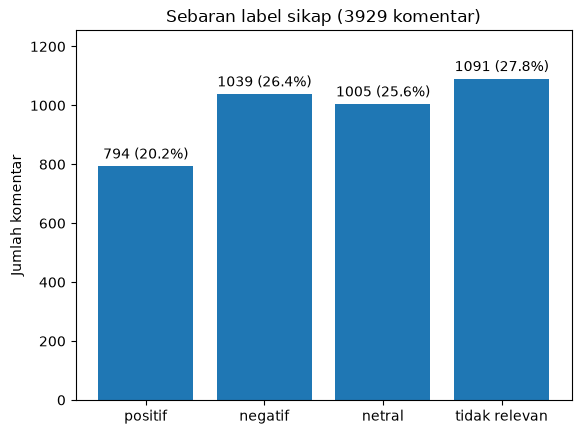

In [80]:
v = data["label"].value_counts().reindex(["positif", "negatif", "netral", "tidak relevan"])

batang = plt.bar(v.index, v.values)
plt.bar_label(batang, labels=[f"{n} ({n / len(data):.1%})" for n in v.values], padding=3)
plt.ylim(0, v.max() * 1.15)
plt.title(f"Sebaran label sikap ({len(data)} komentar)")
plt.ylabel("Jumlah komentar")
plt.show()